In [1]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
DATASET_ROOT = "/home/jovyan/shared/donut/Alzheimer/OAS1"

df = pd.read_excel(f"{DATASET_ROOT}/_oasis_cross-sectional.xlsx")
df = df[df["CDR"].notna()]
df["label"] = (df["CDR"] > 0).astype(int)

def find_file(subject_id):
    pattern = f"{DATASET_ROOT}/{subject_id}/PROCESSED/MPRAGE/T88_111/*_masked_gfc.hdr"
    files = glob.glob(pattern)
    if len(files) == 0:
        return None
    return files[0]

df["path"] = df["ID"].apply(find_file)
df = df[df["path"].notna()]

print("df หลังกรอง:", df.shape)

df หลังกรอง: (234, 14)


In [3]:
df["subject_id"] = df["ID"].apply(lambda x: x.split("_")[1])
subject_labels = df.groupby("subject_id")["label"].first()

subject_ids = list(subject_labels.index)
subject_vals = list(subject_labels.values)

train_subjects, temp_subjects = train_test_split(
    subject_ids, test_size=0.3, stratify=subject_vals, random_state=1334
)

temp_idx_map = dict(zip(subject_ids, subject_vals))
temp_labels_list = [temp_idx_map[s] for s in temp_subjects]

val_subjects, test_subjects = train_test_split(
    temp_subjects, test_size=0.5, stratify=temp_labels_list, random_state=1334
)

# ใส่ชื่อ split ลงในตาราง
df["split"] = "train"
df.loc[df["subject_id"].isin(val_subjects), "split"] = "val"
df.loc[df["subject_id"].isin(test_subjects), "split"] = "test"

# ชื่อกลุ่ม และเพศ (1 = ชาย, 0 = หญิง)
df["group"] = df["label"].map({0: "Normal", 1: "AD"})
df["is_male"] = (df["M/F"] == "M").astype(int)

print(pd.crosstab(df["split"], df["group"]))

group  AD  Normal
split            
test   15      21
train  70      93
val    15      20


In [4]:
by_group = df.groupby("group")

print("จำนวนคน")
print(by_group["Age"].count())
print()
print("อายุเฉลี่ย")
print(by_group["Age"].mean().round(1))
print()
print("อายุน้อยสุด / มากสุด")
print(by_group["Age"].min(), by_group["Age"].max())
print()
print("เปอร์เซ็นต์เพศชาย")
print((by_group["is_male"].mean() * 100).round(1))

จำนวนคน
group
AD        100
Normal    134
Name: Age, dtype: int64

อายุเฉลี่ย
group
AD        76.8
Normal    69.2
Name: Age, dtype: float64

อายุน้อยสุด / มากสุด
group
AD        62
Normal    33
Name: Age, dtype: int64 group
AD        96
Normal    94
Name: Age, dtype: int64

เปอร์เซ็นต์เพศชาย
group
AD        41.0
Normal    28.4
Name: is_male, dtype: float64


In [5]:
by_split = df.groupby(["split", "group"])

result = pd.DataFrame({
    "จำนวนคน": by_split["Age"].count(),
    "อายุเฉลี่ย": by_split["Age"].mean().round(1),
    "อายุน้อยสุด": by_split["Age"].min(),
    "อายุมากสุด": by_split["Age"].max(),
    "เพศชาย %": (by_split["is_male"].mean() * 100).round(1),
})

print(result)

              จำนวนคน  อายุเฉลี่ย  อายุน้อยสุด  อายุมากสุด  เพศชาย %
split group                                                         
test  AD           15        79.5           62          88      46.7
      Normal       21        68.0           39          94      28.6
train AD           70        76.2           63          96      35.7
      Normal       93        68.7           33          93      28.0
val   AD           15        76.5           66          90      60.0
      Normal       20        72.5           48          89      30.0


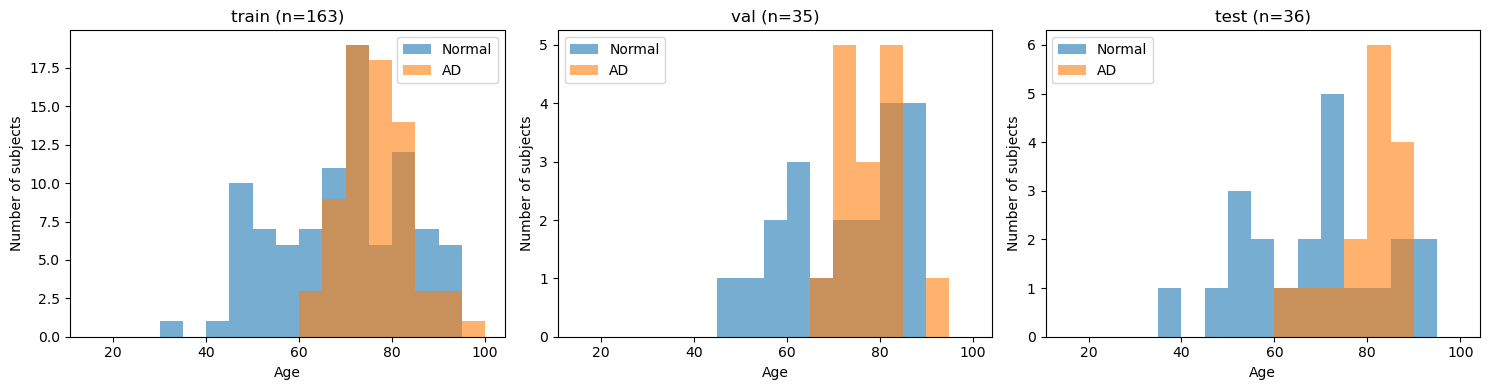

In [6]:
plt.figure(figsize=(15, 4))

for i, s in enumerate(["train", "val", "test"]):

    plt.subplot(1, 3, i + 1)

    part = df[df["split"] == s]
    plt.hist(part[part["group"] == "Normal"]["Age"], bins=range(15, 105, 5), alpha=0.6, label="Normal")
    plt.hist(part[part["group"] == "AD"]["Age"], bins=range(15, 105, 5), alpha=0.6, label="AD")

    plt.title(f"{s} (n={len(part)})")
    plt.xlabel("Age")
    plt.ylabel("Number of subjects")
    plt.legend()

plt.tight_layout()
plt.savefig("age_distribution_by_split.png", dpi=120)
plt.show()

In [7]:
train_part = df[df["split"] == "train"]
val_part = df[df["split"] == "val"]
test_part = df[df["split"] == "test"]

# อายุอย่างเดียว
model_age = LogisticRegression()
model_age.fit(train_part[["Age"]], train_part["label"])

val_auc = roc_auc_score(val_part["label"], model_age.predict_proba(val_part[["Age"]])[:, 1])
test_auc = roc_auc_score(test_part["label"], model_age.predict_proba(test_part[["Age"]])[:, 1])
print("อายุอย่างเดียว  | val AUC:", round(val_auc, 3), "| test AUC:", round(test_auc, 3))

# เพศอย่างเดียว
model_sex = LogisticRegression()
model_sex.fit(train_part[["is_male"]], train_part["label"])

val_auc = roc_auc_score(val_part["label"], model_sex.predict_proba(val_part[["is_male"]])[:, 1])
test_auc = roc_auc_score(test_part["label"], model_sex.predict_proba(test_part[["is_male"]])[:, 1])
print("เพศอย่างเดียว   | val AUC:", round(val_auc, 3), "| test AUC:", round(test_auc, 3))

อายุอย่างเดียว  | val AUC: 0.558 | test AUC: 0.741
เพศอย่างเดียว   | val AUC: 0.65 | test AUC: 0.59


In [8]:
print(pd.crosstab(df["split"], df["CDR"]))

CDR    0.0  0.5  1.0  2.0
split                    
test    21    8    7    0
train   93   50   18    2
val     20   12    3    0
